# Skin Lesion Classification with Fine-Tuned EfficientNet-B0 and Class Imbalance Handling (HAM10000)

**CS4045 Deep Learning for Perception, FAST NUCES Karachi**
Suhaib Raza (23K-0621), Mohid Raheel Khan (23K-3000)

Pipeline, following the proposal:
1. **Phase 1: Data.** HAM10000 from Kaggle (`kmader/skin-cancer-mnist-ham10000`), EDA, and a 70/15/15 split stratified by class and **grouped by `lesion_id`**, so no lesion appears in more than one split.
2. **Phase 2: Model.** EfficientNet-B0 (ImageNet). Stage 1 trains only the new 7-class head; stage 2 unfreezes the last blocks and fine-tunes at lr 1e-4.
3. **Phase 3: Imbalance.** Three runs on the same schedule: (a) plain cross-entropy baseline, (b) class-weighted loss only, (c) `WeightedRandomSampler` only. The winner is chosen by **validation macro-F1**.
4. **Phase 4: Evaluation.** The chosen model is evaluated **once** on the test set: accuracy, balanced accuracy, per-class P/R/F1, confusion matrix, macro ROC-AUC, and Grad-CAM on correct and misclassified cases.

**Before running:** Runtime > Change runtime type > **T4 GPU**. Run cells top to bottom. Each experiment saves to Google Drive and is skipped on re-run, so a disconnect does not lose finished work.

## 0. Setup

In [3]:
%pip install -q grad-cam kagglehub

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
import os, glob, json, random, time
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, tv_tensors
from torchvision.transforms import v2 as T

from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve)

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
print('Device:', DEVICE, torch.cuda.get_device_name(0) if USE_AMP else '')

Device: cuda Tesla T4


In [5]:

IMG_SIZE      = 224
BATCH_SIZE    = 64
EPOCHS_HEAD   = 10      # stage 1: frozen backbone, train head only
EPOCHS_FT     = 10      # stage 2: fine-tune last blocks
LR_HEAD       = 1e-3
LR_FT         = 1e-4
WEIGHT_DECAY  = 1e-5
UNFREEZE_FROM = 6       # EfficientNet-B0 features[0..8]; stage 2 unfreezes features[6:]
NUM_WORKERS   = 2
WEIGHTS       = models.EfficientNet_B0_Weights.IMAGENET1K_V1
FORCE_RETRAIN = False   # True = ignore saved checkpoints and retrain

CLASSES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
CLASS_NAMES = {'akiec': 'Actinic keratoses', 'bcc': 'Basal cell carcinoma',
               'bkl': 'Benign keratosis-like', 'df': 'Dermatofibroma',
               'mel': 'Melanoma', 'nv': 'Melanocytic nevi', 'vasc': 'Vascular lesions'}
NUM_CLASSES = len(CLASSES)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Outputs go to Drive on Colab (survives disconnects), local folder otherwise
try:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_DIR, WORK_DIR = '/content/drive/MyDrive/DLP_Project/outputs', '/content'
except ImportError:
    SAVE_DIR, WORK_DIR = 'outputs', '.'
FIG_DIR = os.path.join(SAVE_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
print('Saving to', SAVE_DIR)

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches='tight')

Mounted at /content/drive
Saving to /content/drive/MyDrive/DLP_Project/outputs


## 1. Phase 1: Data preparation and EDA

`kagglehub` downloads the public dataset straight into Colab. If it asks for credentials, run `kagglehub.login()` once and paste your Kaggle username and API key (Kaggle > Settings > API > Create New Token).

The dataset contains `HAM10000_metadata.csv` (with `lesion_id`, `image_id`, `dx`, `dx_type`, `age`, `sex`, `localization`) and the images split across two folders. Some versions also ship lowercase duplicate folders and `hmnist_*.csv` pixel files; we ignore those and index each `image_id` once.

In [6]:
DATA_ROOT = os.environ.get('HAM_DIR')
if not DATA_ROOT:
    import kagglehub
    DATA_ROOT = kagglehub.dataset_download('kmader/skin-cancer-mnist-ham10000')
print('Data at', DATA_ROOT)

meta = pd.read_csv(os.path.join(DATA_ROOT, 'HAM10000_metadata.csv'))

paths = {}
for p in sorted(glob.glob(os.path.join(DATA_ROOT, '**', '*.jpg'), recursive=True)):
    paths.setdefault(os.path.splitext(os.path.basename(p))[0], p)
meta['path'] = meta['image_id'].map(paths)
assert meta['path'].notna().all(), f"{meta['path'].isna().sum()} images missing"

meta['label'] = meta['dx'].map({c: i for i, c in enumerate(CLASSES)})
meta['idx'] = np.arange(len(meta))   # row index into the image cache
meta.head()

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Data at /kaggle/input/skin-cancer-mnist-ham10000


,lesion_id,image_id,dx,dx_type,age,sex,localization,path,label,idx
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...,2,0
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...,2,1
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...,2,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...,2,3
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...,2,4


In [7]:
counts = meta['dx'].value_counts().reindex(CLASSES)
per_lesion = meta.groupby('lesion_id').size()

print(f'Images         : {len(meta):,}')
print(f'Unique lesions : {meta.lesion_id.nunique():,}')
print(f'Lesions with >1 image: {(per_lesion > 1).sum():,} (max {per_lesion.max()} images for one lesion)')
print(f'Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f} : 1')
print(f'Majority-class baseline accuracy (always predict nv): {counts["nv"] / len(meta):.1%}')
pd.DataFrame({'images': counts, 'share_%': (100 * counts / len(meta)).round(1),
              'lesions': meta.groupby('dx').lesion_id.nunique().reindex(CLASSES)})

Images         : 10,015
Unique lesions : 7,470
Lesions with >1 image: 1,956 (max 6 images for one lesion)
Imbalance ratio (largest / smallest class): 58.3 : 1
Majority-class baseline accuracy (always predict nv): 66.9%


,images,share_%,lesions
dx,,,
akiec,327,3.3,228
bcc,514,5.1,327
bkl,1099,11.0,727
df,115,1.1,73
mel,1113,11.1,614
nv,6705,66.9,5403
vasc,142,1.4,98


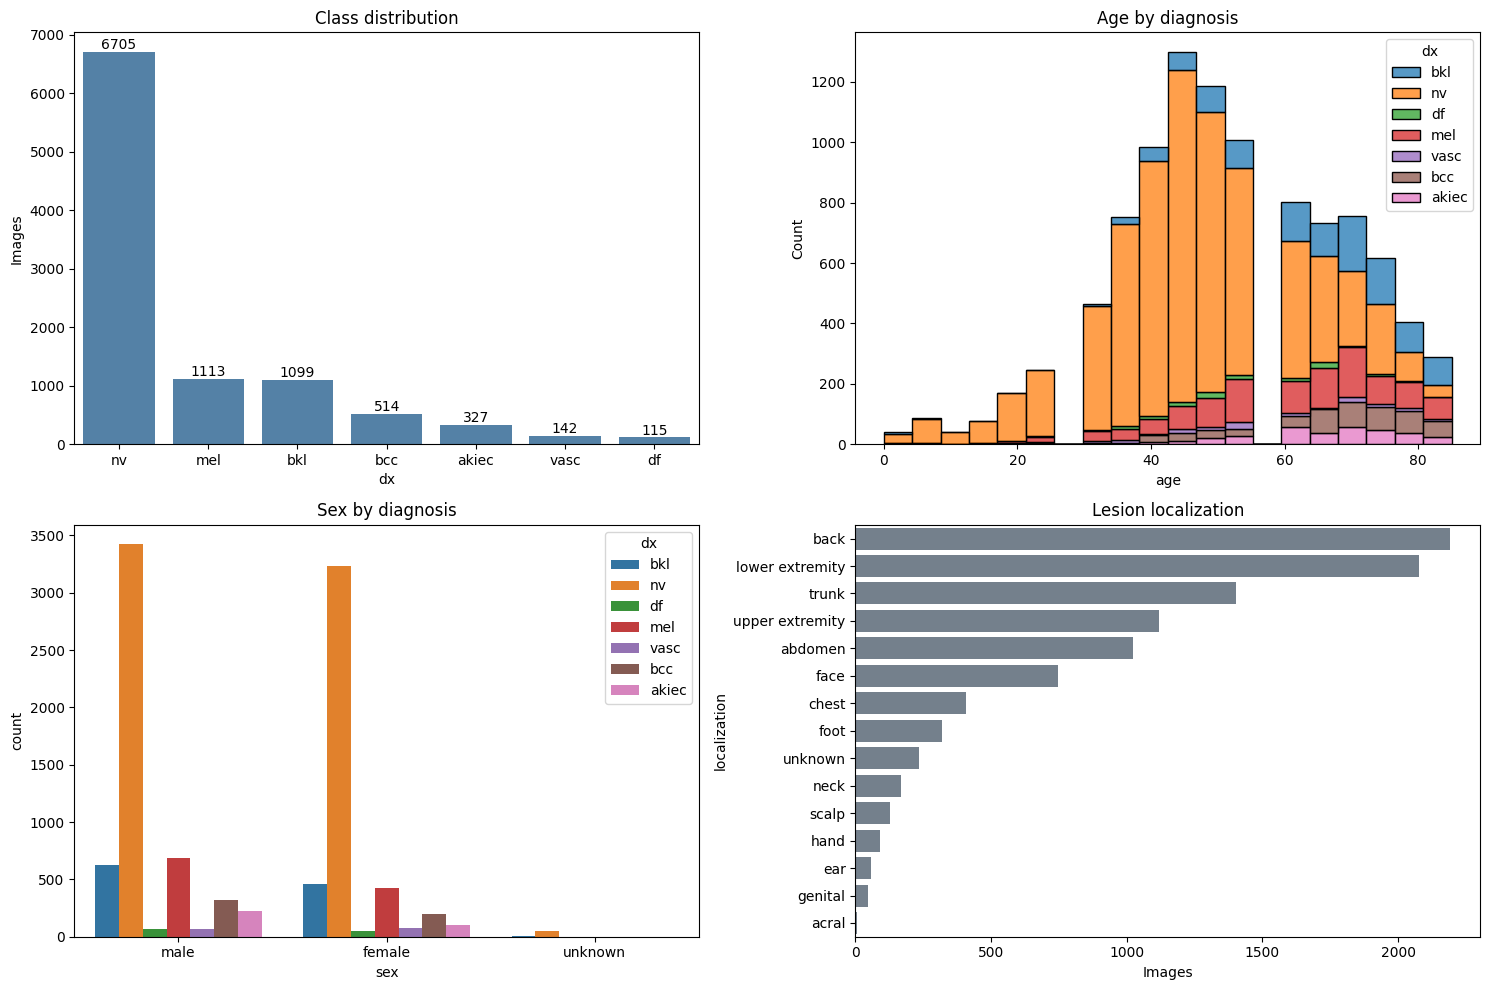

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
order = counts.sort_values(ascending=False).index
sns.barplot(x=order, y=counts[order].values, ax=ax[0, 0], color='steelblue')
for i, v in enumerate(counts[order].values):
    ax[0, 0].text(i, v + 50, str(v), ha='center')
ax[0, 0].set(title='Class distribution', ylabel='Images')

sns.histplot(data=meta, x='age', hue='dx', multiple='stack', bins=20, ax=ax[0, 1])
ax[0, 1].set(title='Age by diagnosis')

sns.countplot(data=meta, x='sex', hue='dx', ax=ax[1, 0])
ax[1, 0].set(title='Sex by diagnosis')

loc = meta['localization'].value_counts()
sns.barplot(y=loc.index, x=loc.values, ax=ax[1, 1], color='slategray')
ax[1, 1].set(title='Lesion localization', xlabel='Images')
plt.tight_layout(); savefig('eda_overview.png'); plt.show()

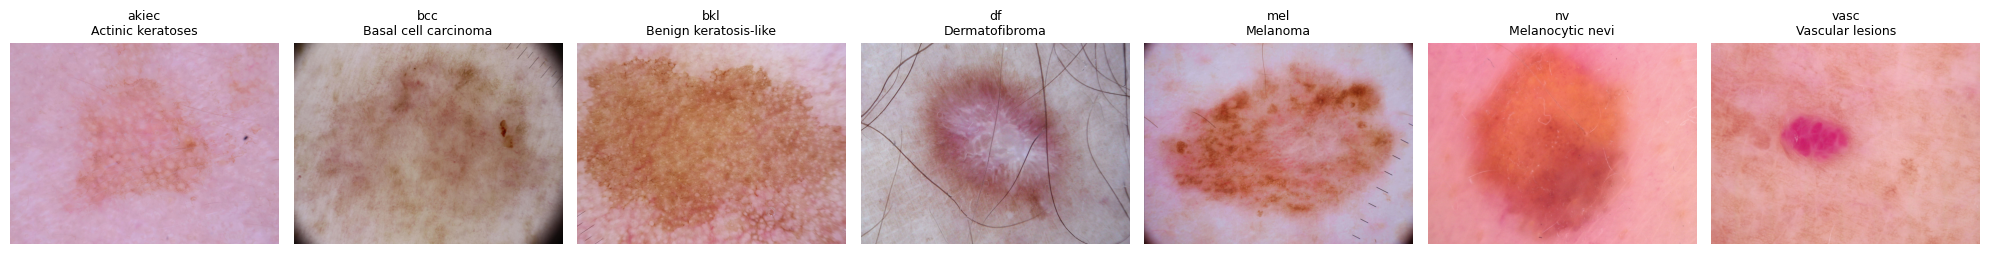

In [9]:
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(20, 3.6))
for ax, c in zip(axes, CLASSES):
    row = meta[meta.dx == c].sample(1, random_state=SEED).iloc[0]
    ax.imshow(Image.open(row.path)); ax.set_title(f'{c}\n{CLASS_NAMES[c]}', fontsize=9); ax.axis('off')
plt.tight_layout(); savefig('sample_images.png'); plt.show()

### Lesion-level split (70 / 15 / 15)

HAM10000 has several images of the same lesion. If those images end up in both train and test, the model is partly tested on lesions it has already seen, and the test score is inflated. We use `StratifiedGroupKFold` with 20 folds (groups = `lesion_id`, stratified by class): 3 folds go to test, 3 to validation and 14 to train.

In [10]:
# How bad would a naive image-level split be? (for the report)
tr_naive, te_naive = train_test_split(meta, test_size=0.15, stratify=meta['label'], random_state=SEED)
shared = set(tr_naive.lesion_id) & set(te_naive.lesion_id)
leaky = te_naive.lesion_id.isin(shared).sum()
print(f'Naive image-level split: {leaky} of {len(te_naive)} test images ({leaky / len(te_naive):.1%}) '
      f'have another image of the same lesion in train.')

Naive image-level split: 606 of 1503 test images (40.3%) have another image of the same lesion in train.


In [11]:
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
fold = np.empty(len(meta), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(meta, meta['label'], groups=meta['lesion_id'])):
    fold[idx] = k
meta['split'] = np.where(fold < 3, 'test', np.where(fold < 6, 'val', 'train'))

train_df, val_df, test_df = (meta[meta.split == s] for s in ['train', 'val', 'test'])

# Leakage checks: must all be empty
L = {s: set(d.lesion_id) for s, d in [('train', train_df), ('val', val_df), ('test', test_df)]}
assert not (L['train'] & L['val']) and not (L['train'] & L['test']) and not (L['val'] & L['test'])
print('No lesion_id is shared between splits.')

summary = pd.crosstab(meta['dx'], meta['split'])[['train', 'val', 'test']].reindex(CLASSES)
summary.loc['TOTAL'] = summary.sum()
summary['train_%'] = (100 * summary['train'] / summary.sum(axis=1)).round(1)
summary

No lesion_id is shared between splits.


split,train,val,test,train_%
dx,,,,
akiec,225,64,38,68.8
bcc,370,74,70,72.0
bkl,758,148,193,69.0
df,81,23,11,70.4
mel,801,157,155,72.0
nv,4686,1010,1009,69.9
vasc,90,26,26,63.4
TOTAL,7011,1502,1502,70.0


### Preprocessing and augmentation

All 10,015 images are resized once from 600x450 to 224x224 and cached in RAM as uint8 (about 1.5 GB). Decoding JPEGs every epoch is the main bottleneck on Colab, so this makes training several times faster.

Augmentation (training set only): random zoom (`RandomResizedCrop`, scale 0.8 to 1.0), horizontal and vertical flips, rotation up to 20 degrees, and colour jitter on brightness, contrast and saturation. All images are normalised with ImageNet mean and std.

In [12]:
CACHE = os.path.join(WORK_DIR, f'ham10000_{IMG_SIZE}.npy')

def load_resized(path):
    return np.asarray(Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))

if os.path.exists(CACHE) and np.load(CACHE, mmap_mode='r').shape[0] == len(meta):
    IMAGES = np.load(CACHE)
else:
    with ThreadPoolExecutor(8) as ex:
        IMAGES = np.stack(list(tqdm(ex.map(load_resized, meta['path']), total=len(meta), desc='Resizing')))
    np.save(CACHE, IMAGES)
print('Image cache:', IMAGES.shape, f'{IMAGES.nbytes / 1e9:.2f} GB')

Resizing:   0%|          | 0/10015 [00:00<?, ?it/s]

Image cache: (10015, 224, 224, 3) 1.51 GB


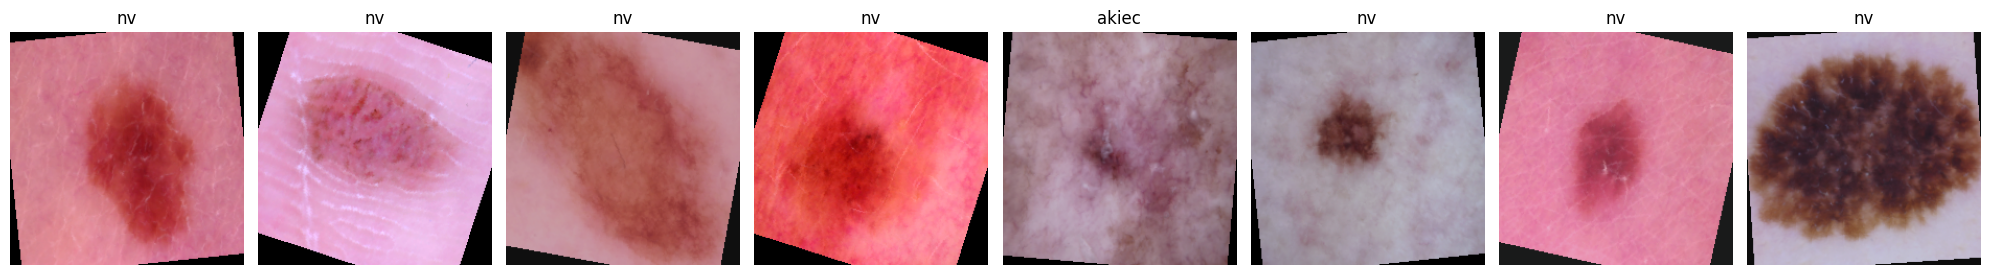

In [13]:
train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1), antialias=True),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomRotation(20),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)])

class LesionDataset(Dataset):
    def __init__(self, df, transform):
        self.idx, self.labels, self.transform = df['idx'].values, df['label'].values, transform
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        x = tv_tensors.Image(torch.from_numpy(IMAGES[self.idx[i]]).permute(2, 0, 1))
        return self.transform(x).as_subclass(torch.Tensor), int(self.labels[i])

train_counts = np.bincount(train_df['label'], minlength=NUM_CLASSES)

def make_loader(df, train, sampler=None):
    return DataLoader(LesionDataset(df, train_tf if train else eval_tf), batch_size=BATCH_SIZE,
                      shuffle=(train and sampler is None), sampler=sampler,
                      num_workers=NUM_WORKERS, pin_memory=USE_AMP, drop_last=False,
                      generator=torch.Generator().manual_seed(SEED))

val_loader, test_loader = make_loader(val_df, False), make_loader(test_df, False)

# Quick look at augmented training images
xb, yb = next(iter(make_loader(train_df, True)))
grid = (xb[:8].permute(0, 2, 3, 1) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1)
fig, axes = plt.subplots(1, 8, figsize=(20, 3))
for a, im, y in zip(axes, grid, yb[:8]):
    a.imshow(im); a.set_title(CLASSES[y]); a.axis('off')
plt.tight_layout(); savefig('augmented_batch.png'); plt.show()

## 2. Phase 2: Model and two-stage transfer learning

- **Stage 1 (feature extraction):** the whole backbone is frozen and only the new head (`Dropout 0.3 -> Linear 1280->7`) is trained at lr 1e-3.
- **Stage 2 (fine-tuning):** `features[6:]` (the last MBConv blocks plus the final 1x1 conv) are unfrozen and trained with the head at lr 1e-4, using cosine decay.

Frozen layers are kept in `eval()` mode so their BatchNorm statistics stay at the ImageNet values instead of drifting with our small batches.

In [14]:
def build_model():
    m = models.efficientnet_b0(weights=WEIGHTS)
    m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[1].in_features, NUM_CLASSES))
    return m.to(DEVICE)

def set_stage(m, stage):
    for p in m.parameters():
        p.requires_grad = False
    for p in m.classifier.parameters():
        p.requires_grad = True
    if stage == 2:
        for p in m.features[UNFREEZE_FROM:].parameters():
            p.requires_grad = True

def train_mode(m, stage):
    m.train()
    (m.features if stage == 1 else m.features[:UNFREEZE_FROM]).eval()   # freeze BN stats of frozen part

m = build_model()
for s in (1, 2):
    set_stage(m, s)
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'Stage {s}: {n:,} trainable of {sum(p.numel() for p in m.parameters()):,} parameters')
del m

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 142MB/s]


Stage 1: 8,967 trainable of 4,016,515 parameters
Stage 2: 3,164,707 trainable of 4,016,515 parameters


In [15]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x.to(DEVICE, non_blocking=True))
        probs.append(torch.softmax(out.float(), 1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(probs).numpy()

def compute_metrics(y, probs):
    pred = probs.argmax(1)
    return {
        'accuracy':     accuracy_score(y, pred),
        'balanced_acc': balanced_accuracy_score(y, pred),
        'macro_f1':     f1_score(y, pred, average='macro', zero_division=0),
        'weighted_f1':  f1_score(y, pred, average='weighted', zero_division=0),
        'roc_auc':      roc_auc_score(y, probs, multi_class='ovr', average='macro', labels=list(range(NUM_CLASSES))),
        'val_loss':     float(nn.functional.nll_loss(torch.log(torch.tensor(probs) + 1e-9), torch.tensor(y))),
    }

def train_one_epoch(model, loader, criterion, optimizer, scaler, stage):
    train_mode(model, stage)
    total, correct, loss_sum = 0, 0, 0.0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x)
            loss = criterion(out, y)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        loss_sum += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); total += len(y)
    return loss_sum / total, correct / total

## 3. Phase 3: Class imbalance handling

Three experiments, identical apart from the imbalance strategy:

| Experiment | Loss | Sampling |
|---|---|---|
| `baseline` | plain cross-entropy | uniform shuffle |
| `weighted_loss` | cross-entropy with weights `N / (K * n_c)` | uniform shuffle |
| `oversampling` | plain cross-entropy | `WeightedRandomSampler`, each class roughly equally likely per batch |

Weighted loss and oversampling are **never combined**. Each one fully rebalances on its own, so stacking them over-corrects and pushes the model away from the majority class.

Checkpoints are selected on **validation macro-F1**, not accuracy, because accuracy rewards predicting `nv`.

In [16]:
def run_experiment(name, class_weighted=False, oversample=False):
    ckpt, hist_path = os.path.join(SAVE_DIR, f'{name}_best.pt'), os.path.join(SAVE_DIR, f'{name}_history.json')
    if not FORCE_RETRAIN and os.path.exists(ckpt) and os.path.exists(hist_path):
        print(f'[{name}] found saved run, skipping training.')
        return json.load(open(hist_path))

    seed_everything()
    model = build_model()
    weights = torch.tensor(len(train_df) / (NUM_CLASSES * train_counts), dtype=torch.float32)
    criterion = nn.CrossEntropyLoss(weight=weights.to(DEVICE) if class_weighted else None)
    sampler = None
    if oversample:
        sample_w = (1.0 / train_counts)[train_df['label'].values]
        sampler = WeightedRandomSampler(torch.tensor(sample_w, dtype=torch.double), len(sample_w), replacement=True,
                                        generator=torch.Generator().manual_seed(SEED))
    train_loader = make_loader(train_df, True, sampler)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)

    history, best = [], {'macro_f1': -1}
    for stage, epochs, lr in [(1, EPOCHS_HEAD, LR_HEAD), (2, EPOCHS_FT, LR_FT)]:
        set_stage(model, stage)
        opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=WEIGHT_DECAY)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        for ep in range(1, epochs + 1):
            t0 = time.time()
            tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, opt, scaler, stage)
            sched.step()
            m = compute_metrics(*predict(model, val_loader))
            row = {'stage': stage, 'epoch': len(history) + 1, 'train_loss': tr_loss, 'train_acc': tr_acc, **m}
            history.append(row)
            flag = ''
            if m['macro_f1'] > best['macro_f1']:
                best = dict(row); torch.save(model.state_dict(), ckpt); flag = '  * best'
            print(f"[{name}] S{stage} ep {row['epoch']:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
                  f"val acc {m['accuracy']:.3f} bal {m['balanced_acc']:.3f} mF1 {m['macro_f1']:.3f} "
                  f"AUC {m['roc_auc']:.3f} | {time.time() - t0:.0f}s{flag}")
    result = {'name': name, 'best': best, 'history': history}
    json.dump(result, open(hist_path, 'w'), indent=1)
    del model; torch.cuda.empty_cache()
    return result

In [17]:
EXPERIMENTS = {
    'baseline':      dict(class_weighted=False, oversample=False),
    'weighted_loss': dict(class_weighted=True,  oversample=False),
    'oversampling':  dict(class_weighted=False, oversample=True),
}
results = {name: run_experiment(name, **cfg) for name, cfg in EXPERIMENTS.items()}

[baseline] found saved run, skipping training.
[weighted_loss] found saved run, skipping training.
[oversampling] found saved run, skipping training.


In [18]:
cols = ['epoch', 'accuracy', 'balanced_acc', 'macro_f1', 'weighted_f1', 'roc_auc']
comparison = pd.DataFrame({n: {c: r['best'][c] for c in cols} for n, r in results.items()}).T
comparison['epoch'] = comparison['epoch'].astype(int)
comparison = comparison.rename(columns={'epoch': 'best_epoch'})
print('Validation metrics at each run\'s best epoch (selected by macro-F1):')
display(comparison.style.format({c: '{:.3f}' for c in cols[1:]}).highlight_max(subset=cols[1:], color='#cde8cd'))
comparison.to_csv(os.path.join(SAVE_DIR, 'imbalance_comparison_val.csv'))

BEST = comparison['macro_f1'].idxmax()
print(f'Selected strategy: {BEST}')

Validation metrics at each run's best epoch (selected by macro-F1):


,best_epoch,accuracy,balanced_acc,macro_f1,weighted_f1,roc_auc
baseline,17,0.799,0.640,0.649,0.797,0.952
weighted_loss,20,0.703,0.695,0.617,0.730,0.941
oversampling,17,0.728,0.707,0.645,0.752,0.946


Selected strategy: baseline


### Stage-1 baseline (frozen backbone only)

The proposal defines the frozen-backbone model (stage 1, head only) as the baseline. Below: (A) the best stage-1 validation metrics of each run, read from the saved histories, and (B) a stage-1-only model evaluated on the test set. In the rest of this notebook, `baseline` means *no imbalance correction*; *frozen backbone* means stage 1 only.

In [19]:

cols = ['epoch', 'accuracy', 'balanced_acc', 'macro_f1', 'weighted_f1', 'roc_auc']
rows = {}
for name, r in results.items():
    h = pd.DataFrame(r['history'])
    s1 = h[h.stage == 1]
    rows[name] = s1.loc[s1.macro_f1.idxmax(), cols]
stage1_val = pd.DataFrame(rows).T
print('Best validation metrics during stage 1 (frozen backbone):')
print(stage1_val.round(3).to_string())
stage1_val.to_csv(os.path.join(SAVE_DIR, 'stage1_frozen_val.csv'))

Best validation metrics during stage 1 (frozen backbone):
               epoch  accuracy  balanced_acc  macro_f1  weighted_f1  roc_auc
baseline         8.0     0.756         0.461     0.490        0.746    0.915
weighted_loss    5.0     0.601         0.605     0.469        0.643    0.898
oversampling     7.0     0.589         0.630     0.465        0.634    0.904


In [20]:
def run_stage1_only(name='stage1_frozen'):
    ckpt = os.path.join(SAVE_DIR, f'{name}_best.pt')
    if FORCE_RETRAIN or not os.path.exists(ckpt):
        seed_everything()
        model = build_model(); set_stage(model, 1)
        criterion = nn.CrossEntropyLoss()
        loader = make_loader(train_df, True)
        scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
        opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad],
                               lr=LR_HEAD, weight_decay=WEIGHT_DECAY)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_HEAD)
        best = -1
        for ep in range(1, EPOCHS_HEAD + 1):
            train_one_epoch(model, loader, criterion, opt, scaler, 1); sched.step()
            m = compute_metrics(*predict(model, val_loader))
            if m['macro_f1'] > best:
                best = m['macro_f1']; torch.save(model.state_dict(), ckpt)
            print(f"[{name}] ep {ep:2d} | val acc {m['accuracy']:.3f} mF1 {m['macro_f1']:.3f}")
        del model
    model = build_model()
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    y, p = predict(model, test_loader)
    mets = compute_metrics(y, p); mets.pop('val_loss')
    print(classification_report(y, p.argmax(1), target_names=CLASSES, digits=3, zero_division=0))
    del model; torch.cuda.empty_cache()
    return mets

stage1_test = run_stage1_only()
print('Stage 1 (frozen backbone) test:', {k: round(float(v), 4) for k, v in stage1_test.items()})
json.dump({k: float(v) for k, v in stage1_test.items()},
          open(os.path.join(SAVE_DIR, 'stage1_frozen_test.json'), 'w'), indent=1)

[stage1_frozen] ep  1 | val acc 0.713 mF1 0.307
[stage1_frozen] ep  2 | val acc 0.732 mF1 0.381
[stage1_frozen] ep  3 | val acc 0.738 mF1 0.435
[stage1_frozen] ep  4 | val acc 0.729 mF1 0.425
[stage1_frozen] ep  5 | val acc 0.754 mF1 0.465
[stage1_frozen] ep  6 | val acc 0.750 mF1 0.479
[stage1_frozen] ep  7 | val acc 0.752 mF1 0.473
[stage1_frozen] ep  8 | val acc 0.756 mF1 0.490
[stage1_frozen] ep  9 | val acc 0.752 mF1 0.486
[stage1_frozen] ep 10 | val acc 0.752 mF1 0.484
              precision    recall  f1-score   support

       akiec      0.333     0.263     0.294        38
         bcc      0.460     0.414     0.436        70
         bkl      0.459     0.523     0.489       193
          df      0.000     0.000     0.000        11
         mel      0.408     0.316     0.356       155
          nv      0.855     0.894     0.874      1009
        vasc      1.000     0.462     0.632        26

    accuracy                          0.734      1502
   macro avg      0.502     0.41

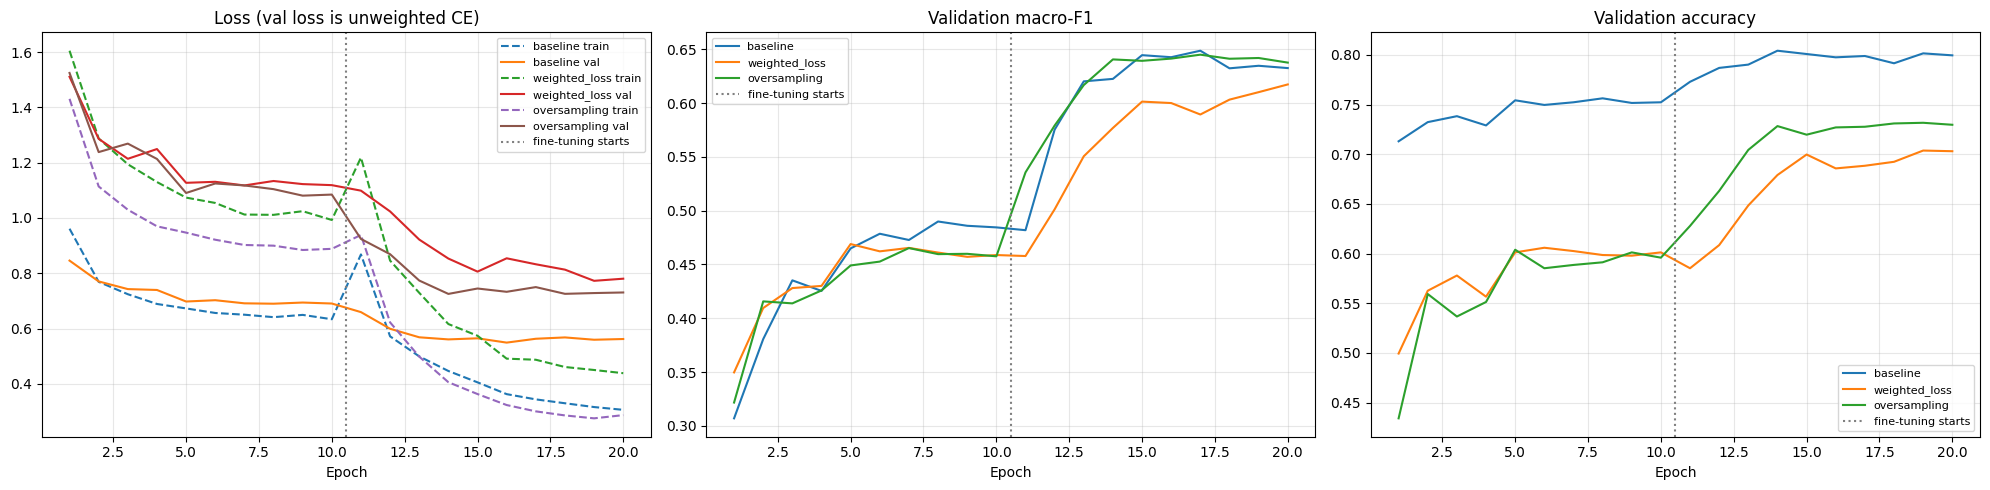

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for name, r in results.items():
    h = pd.DataFrame(r['history'])
    axes[0].plot(h.epoch, h.train_loss, '--', label=f'{name} train')
    axes[0].plot(h.epoch, h.val_loss, label=f'{name} val')
    axes[1].plot(h.epoch, h.macro_f1, label=name)
    axes[2].plot(h.epoch, h.accuracy, label=name)
for a, t in zip(axes, ['Loss (val loss is unweighted CE)', 'Validation macro-F1', 'Validation accuracy']):
    a.axvline(EPOCHS_HEAD + 0.5, color='gray', ls=':', label='fine-tuning starts'); a.set(title=t, xlabel='Epoch')
    a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); savefig('training_curves.png'); plt.show()

## 4. Phase 4: Final evaluation on the held-out test set

Only the selected model is evaluated on the test set, once.

In [22]:
model = build_model()
model.load_state_dict(torch.load(os.path.join(SAVE_DIR, f'{BEST}_best.pt'), map_location=DEVICE))
y_test, p_test = predict(model, test_loader)
pred_test = p_test.argmax(1)
test_metrics = compute_metrics(y_test, p_test)
test_metrics.pop('val_loss')

print(f'TEST RESULTS ({BEST}, n = {len(y_test)})')
for k, v in test_metrics.items():
    print(f'  {k:<13}: {v:.4f}')
print()
print(classification_report(y_test, pred_test, target_names=CLASSES, digits=3, zero_division=0))

json.dump({'model': BEST, **test_metrics,
           'report': classification_report(y_test, pred_test, target_names=CLASSES, output_dict=True, zero_division=0)},
          open(os.path.join(SAVE_DIR, 'test_results.json'), 'w'), indent=1)

TEST RESULTS (baseline, n = 1502)
  accuracy     : 0.7956
  balanced_acc : 0.5645
  macro_f1     : 0.5872
  weighted_f1  : 0.7891
  roc_auc      : 0.9431

              precision    recall  f1-score   support

       akiec      0.545     0.316     0.400        38
         bcc      0.702     0.571     0.630        70
         bkl      0.607     0.663     0.634       193
          df      0.333     0.273     0.300        11
         mel      0.477     0.400     0.435       155
          nv      0.887     0.921     0.904      1009
        vasc      0.808     0.808     0.808        26

    accuracy                          0.796      1502
   macro avg      0.623     0.565     0.587      1502
weighted avg      0.786     0.796     0.789      1502



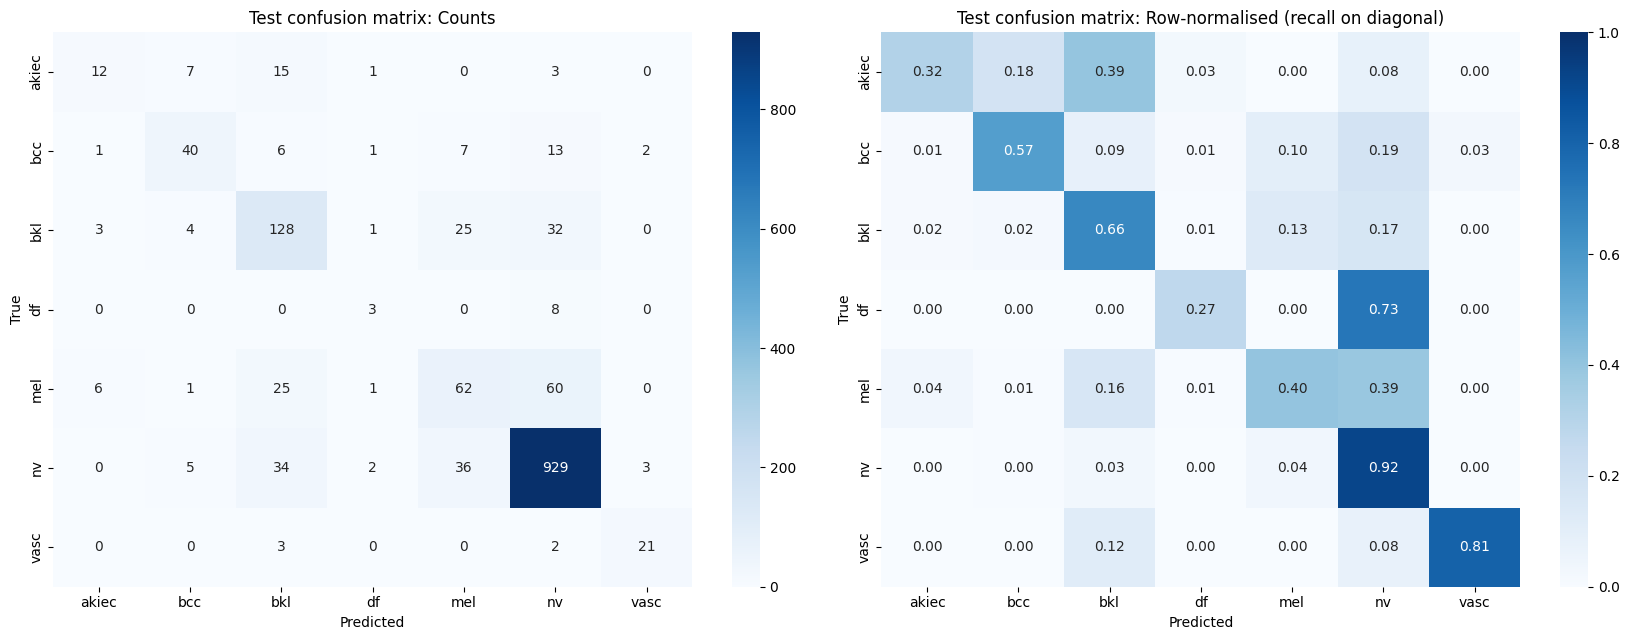

In [23]:
cm = confusion_matrix(y_test, pred_test, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
for a, t in zip(ax, ['Counts', 'Row-normalised (recall on diagonal)']):
    a.set(title=f'Test confusion matrix: {t}', xlabel='Predicted', ylabel='True')
plt.tight_layout(); savefig('confusion_matrix.png'); plt.show()

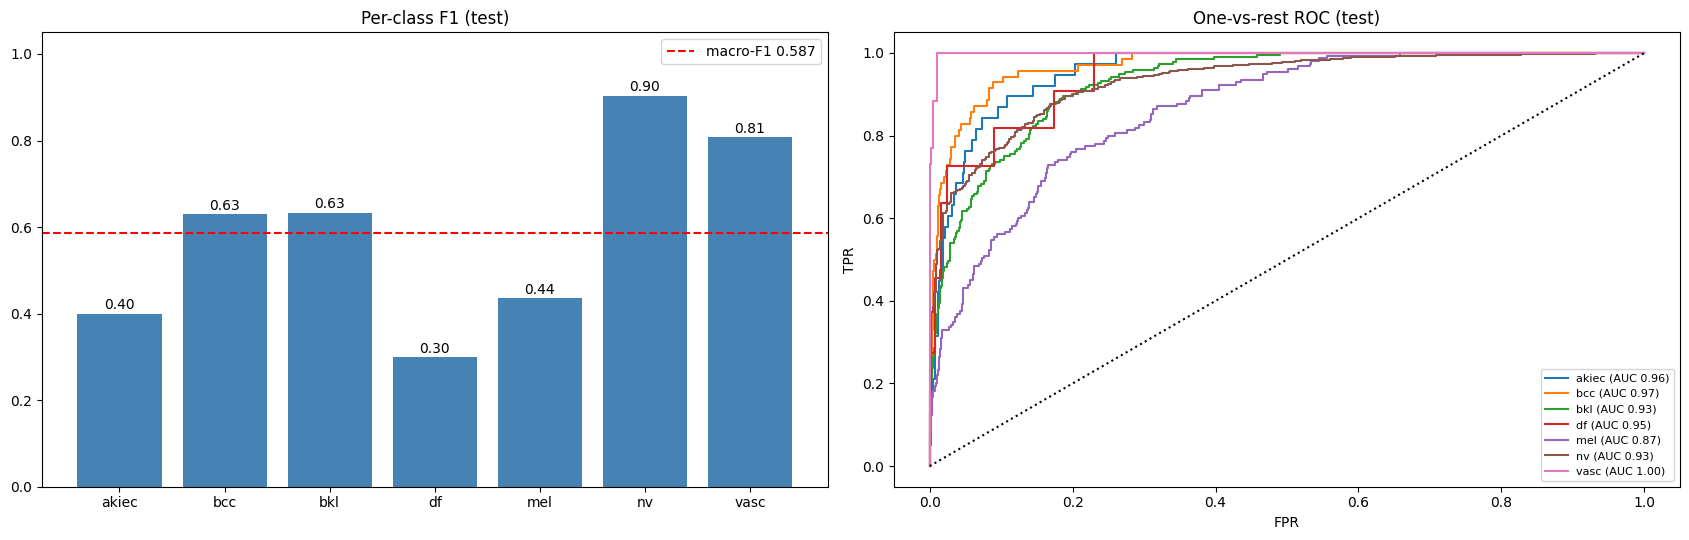

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
f1s = f1_score(y_test, pred_test, average=None, labels=range(NUM_CLASSES), zero_division=0)
ax[0].bar(CLASSES, f1s, color='steelblue')
for i, v in enumerate(f1s):
    ax[0].text(i, v + 0.01, f'{v:.2f}', ha='center')
ax[0].axhline(test_metrics['macro_f1'], color='red', ls='--', label=f"macro-F1 {test_metrics['macro_f1']:.3f}")
ax[0].set(title='Per-class F1 (test)', ylim=(0, 1.05)); ax[0].legend()

for i, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_test == i, p_test[:, i])
    ax[1].plot(fpr, tpr, label=f'{c} (AUC {roc_auc_score(y_test == i, p_test[:, i]):.2f})')
ax[1].plot([0, 1], [0, 1], 'k:'); ax[1].set(title='One-vs-rest ROC (test)', xlabel='FPR', ylabel='TPR'); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('f1_and_roc.png'); plt.show()

### Grad-CAM

Heatmaps from the last convolutional block (`features[-1]`) for the predicted class. Row set 1: one correctly classified test image per class. Row set 2: misclassified test images, to check whether errors come from attending to the wrong region (hair, ruler marks, vignetting) or from visually ambiguous lesions.

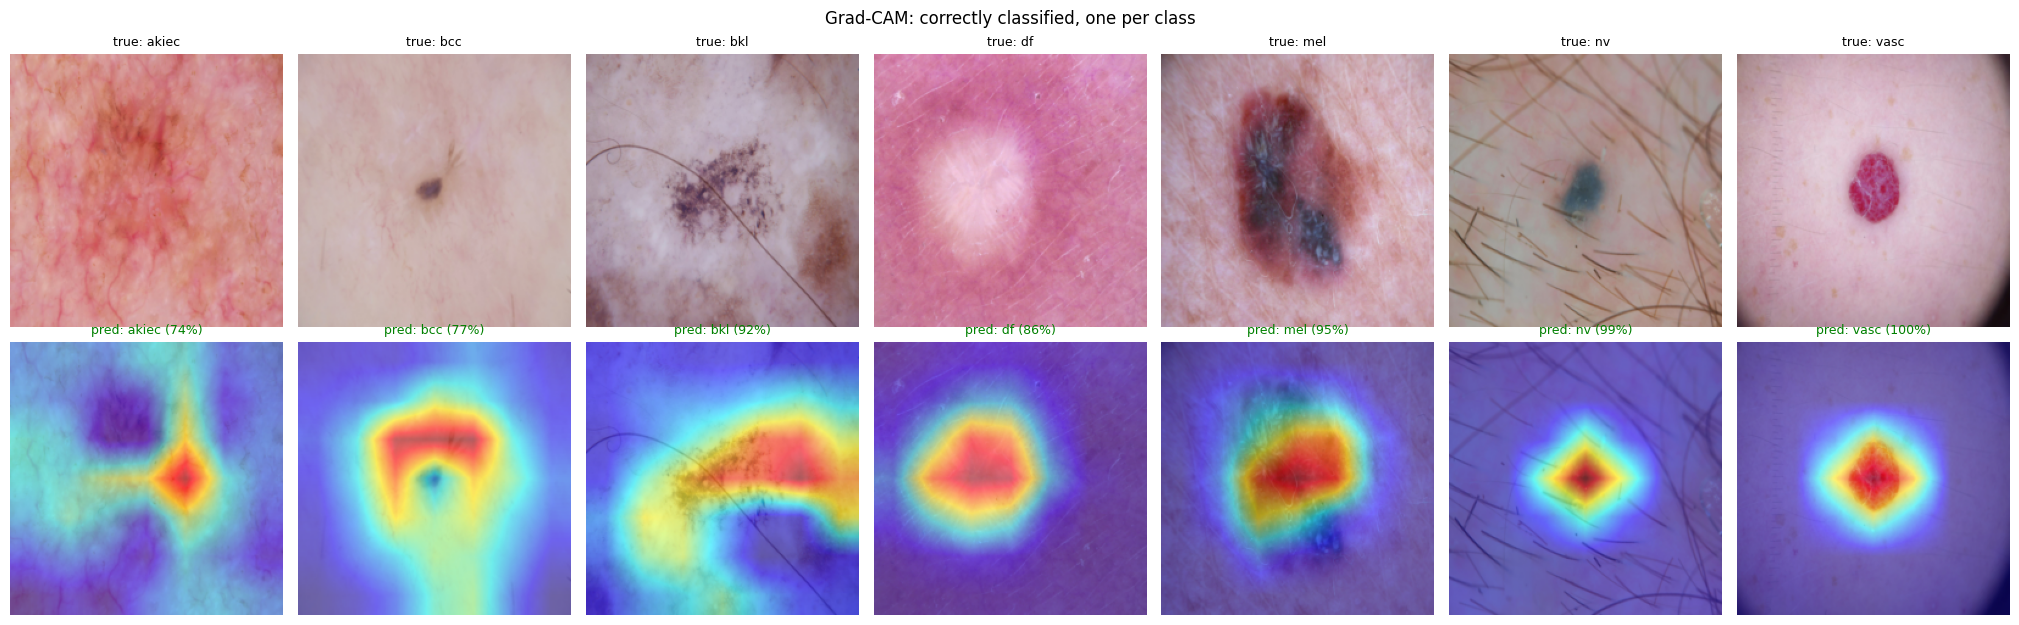

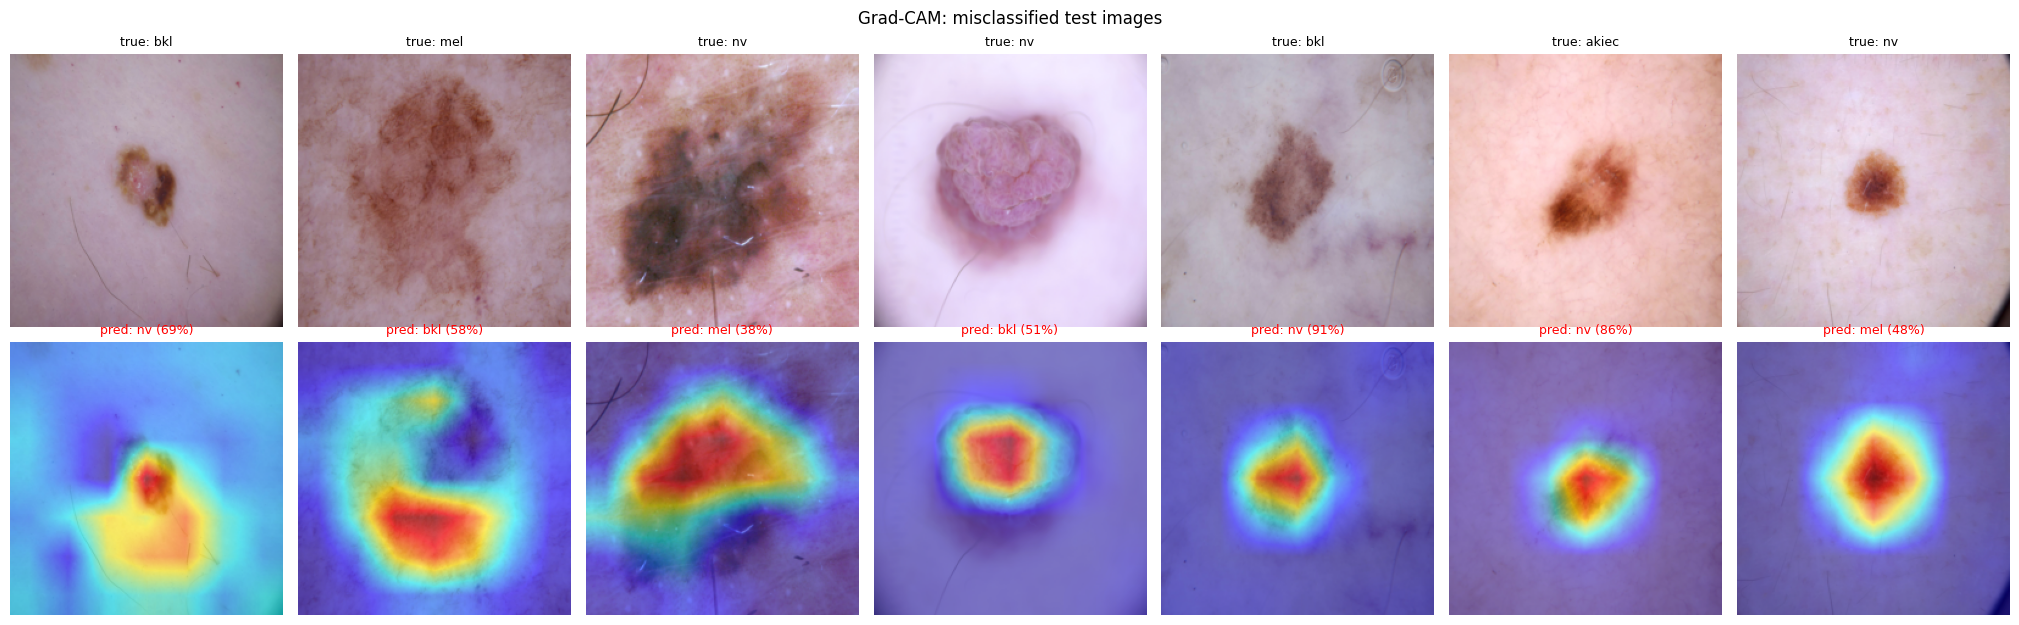

In [25]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

model.eval()
for p in model.parameters():
    p.requires_grad_(True)
cam = GradCAM(model=model, target_layers=[model.features[-1]])
test_rows = test_df.reset_index(drop=True)

def gradcam_grid(positions, title, fname):
    fig, axes = plt.subplots(2, len(positions), figsize=(2.9 * len(positions), 6.4))
    axes = np.array(axes).reshape(2, -1)
    for j, pos in enumerate(positions):
        row = test_rows.iloc[pos]
        rgb = IMAGES[row['idx']]
        x = eval_tf(tv_tensors.Image(torch.from_numpy(rgb).permute(2, 0, 1))).as_subclass(torch.Tensor)[None].to(DEVICE)
        pred = int(pred_test[pos])
        heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(pred)])[0]
        axes[0, j].imshow(rgb); axes[0, j].set_title(f'true: {CLASSES[row.label]}', fontsize=9)
        axes[1, j].imshow(show_cam_on_image(rgb / 255.0, heat, use_rgb=True))
        ok = pred == row.label
        axes[1, j].set_title(f'pred: {CLASSES[pred]} ({p_test[pos, pred]:.0%})', fontsize=9, color='green' if ok else 'red')
        for a in axes[:, j]:
            a.axis('off')
    plt.suptitle(title); plt.tight_layout(); savefig(fname); plt.show()

rng = np.random.default_rng(SEED)
correct_per_class = []
for i in range(NUM_CLASSES):
    hits = np.where((y_test == i) & (pred_test == i))[0]
    if len(hits):
        correct_per_class.append(int(rng.choice(hits)))
gradcam_grid(correct_per_class, 'Grad-CAM: correctly classified, one per class', 'gradcam_correct.png')

wrong = np.where(y_test != pred_test)[0]
gradcam_grid([int(i) for i in rng.choice(wrong, size=min(7, len(wrong)), replace=False)],
             'Grad-CAM: misclassified test images', 'gradcam_misclassified.png')

## 5. Summary

In [26]:
print('Validation comparison of imbalance strategies (best epoch by macro-F1):')
print(comparison.round(3).to_string())
print(f'\nSelected: {BEST}')
print('Test set:', {k: round(v, 4) for k, v in test_metrics.items()})
print('\nAll figures, checkpoints and JSON results are in', SAVE_DIR)

Validation comparison of imbalance strategies (best epoch by macro-F1):
               best_epoch  accuracy  balanced_acc  macro_f1  weighted_f1  roc_auc
baseline               17     0.799         0.640     0.649        0.797    0.952
weighted_loss          20     0.703         0.695     0.617        0.730    0.941
oversampling           17     0.728         0.707     0.645        0.752    0.946

Selected: baseline
Test set: {'accuracy': 0.7956, 'balanced_acc': np.float64(0.5645), 'macro_f1': 0.5872, 'weighted_f1': 0.7891, 'roc_auc': np.float64(0.9431)}

All figures, checkpoints and JSON results are in /content/drive/MyDrive/DLP_Project/outputs


**Notes for the report**
- Test numbers come from a lesion-level split, so they are expected to be somewhat lower than papers or notebooks that split by image. The leakage check in Phase 1 gives the exact percentage of test images that a naive split would have leaked.
- Macro-F1 and balanced accuracy are the primary metrics. Overall accuracy is reported but can be misleading, because always predicting `nv` already scores about 67%.
- Grad-CAM shows where the model looks, not why it is correct. Use it to discuss failure cases, not as proof of clinical validity.

In [27]:
m2 = build_model()
m2.load_state_dict(torch.load(os.path.join(SAVE_DIR, 'oversampling_best.pt'), map_location=DEVICE))
y2, p2 = predict(m2, test_loader)
print(compute_metrics(y2, p2))
print(classification_report(y2, p2.argmax(1), target_names=CLASSES, digits=3))

{'accuracy': 0.7190412782956058, 'balanced_acc': np.float64(0.6737905511161072), 'macro_f1': 0.5972599653906566, 'weighted_f1': 0.7433968552187993, 'roc_auc': np.float64(0.9407734323459743), 'val_loss': 0.7448356747627258}
              precision    recall  f1-score   support

       akiec      0.444     0.421     0.432        38
         bcc      0.642     0.743     0.689        70
         bkl      0.519     0.694     0.594       193
          df      0.304     0.636     0.412        11
         mel      0.329     0.587     0.421       155
          nv      0.952     0.750     0.839      1009
        vasc      0.719     0.885     0.793        26

    accuracy                          0.719      1502
   macro avg      0.559     0.674     0.597      1502
weighted avg      0.796     0.719     0.743      1502

